## Configuration and Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer
from tqdm import tqdm

tqdm.pandas()

# --- CONFIGURATION ---
MODEL_ID = "meta-llama/Meta-Llama-3.1-8B-Instruct"
DATASET_PATH = "ozgur-coban/medical-lora-10k"
DATASET_SPLIT = "train"


## EDA

In [2]:
def run_medical_eda():
    print(f"1. Loading Dataset ({DATASET_PATH}) and Tokenizer...")
    # Load directly from your HF repo
    dataset = load_dataset(DATASET_PATH, split=DATASET_SPLIT)
    train_df = dataset.to_pandas()

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

    print("\n2. Analyzing Structural Integrity...")
    # Basic health checks for the new dataset structure
    empty_inputs = train_df[train_df["input"].str.strip() == ""]
    empty_outputs = train_df[train_df["output"].str.strip() == ""]

    print(f"Total rows: {len(train_df)}")
    print(f"Rows with empty inputs: {len(empty_inputs)}")
    print(f"Rows with empty outputs: {len(empty_outputs)}")

    print("\n3. Calculating Token Length Distributions (This may take a minute)...")

    def calculate_lengths(row):
        messages = [
            {"role": "system", "content": row["instruction"]},
            {"role": "user", "content": row["input"]},
            {"role": "assistant", "content": row["output"]},
        ]

        # Apply Llama-3 chat template
        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)
        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        # Count tokens
        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    # Using progress_apply because 10,000 rows takes a bit of time to tokenize
    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = (
        train_df.progress_apply(calculate_lengths, axis=1)
    )

    print("\nToken Length Percentiles:")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length (Diagnoses)")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Symptom Check)...")
    # Custom stop words to remove generic medical conversational filler
    custom_stops = list(CountVectorizer(stop_words="english").get_stop_words()) + [
        "doctor",
        "hello",
        "hi",
        "help",
        "experiencing",
        "symptoms",
        "feel",
        "like",
    ]

    vectorizer = CountVectorizer(stop_words=custom_stops, max_features=20)
    word_counts = vectorizer.fit_transform(train_df["input"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="mako")
    plt.title("Top 20 Informative Words in Patient Inputs")
    plt.show()


## Execution

1. Loading Dataset (ozgur-coban/medical-lora-10k) and Tokenizer...


README.md:   0%|          | 0.00/353 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/5.00M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10452 [00:00<?, ? examples/s]


2. Analyzing Structural Integrity...
Total rows: 10452
Rows with empty inputs: 0
Rows with empty outputs: 0

3. Calculating Token Length Distributions (This may take a minute)...


100%|██████████| 10452/10452 [00:11<00:00, 898.76it/s]



Token Length Percentiles:
       prompt_tokens  completion_tokens  total_tokens
count   10452.000000       10452.000000  10452.000000
mean      129.708381         123.302239    253.010620
std        73.395000          90.673907    146.969044
min        69.000000           9.000000     83.000000
50%       100.000000         103.000000    205.000000
90%       217.000000         252.000000    456.000000
95%       276.000000         290.450000    537.000000
99%       442.490000         369.490000    726.000000
max       878.000000         796.000000   1251.000000

4. Plotting Distributions...


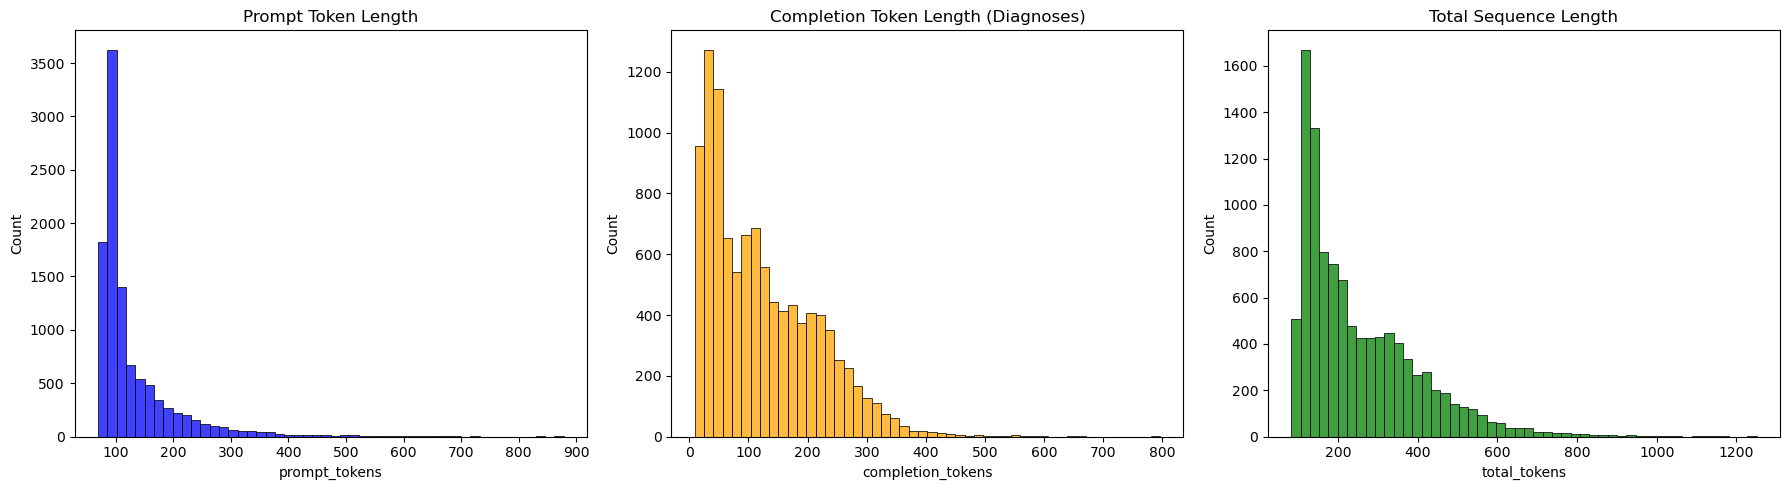


5. Vocabulary Frequency Analysis (Symptom Check)...


C:\Users\ozgur\AppData\Local\Temp\ipykernel_22600\2208103244.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette="mako")


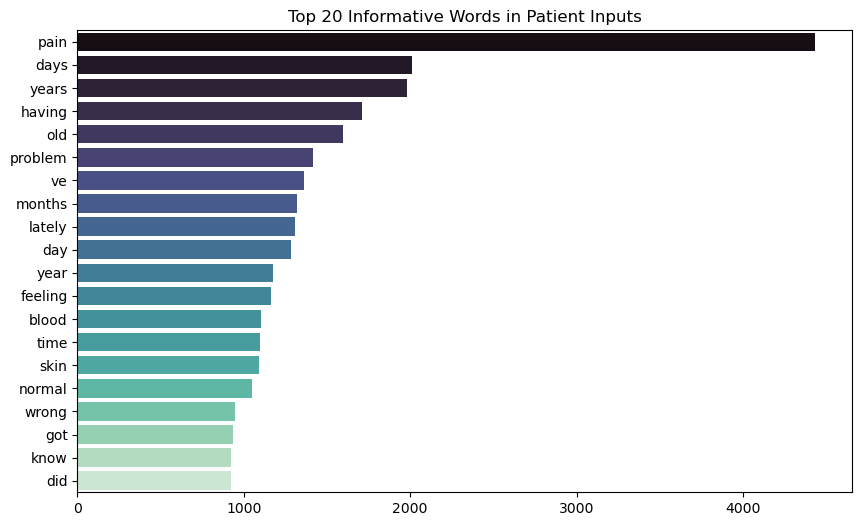

In [3]:
if __name__ == "__main__":
    run_medical_eda()
